# Large-Scale Streaming Analysis: Out-of-Core Processing for 100k to 1M+ Frames

[![Open in JupyterLab](https://img.shields.io/badge/Launch-JupyterLab-orange.svg)](https://jupyter.org)
[![Python 3.10+](https://img.shields.io/badge/python-3.10+-blue.svg)](https://www.python.org/)

Modern molecular dynamics simulations routinely generate hundreds of gigabytes of trajectory data across hundreds of thousands of frames. Attempting to load an entire $100{,}000 \times 4{,}000$ numerical matrix into RAM causes catastrophic Out-Of-Memory (OOM) crashes.

MolScope solves this through an **out-of-core streaming architecture**:
1. **Checksummed CSV Chunking**: Features are extracted and committed in atomic, checksummed chunks.
2. **Algorithm R Uniform Reservoir Sampling**: A fixed-size reservoir sample ($S = 2,000$ rows) estimates scaling, PCA, and initial state centers.
3. **Bounded Two-Pass Assignment**: A second pass assigns every trajectory frame in bounded batches, accumulating running moments.
4. **Strict $O(1)$ Memory Scaling**: Process memory footprint remains flat at ~260–290 MiB regardless of trajectory length.

## 1. Streaming Architecture Overview

```text
[Trajectory Stream] ──► [Chunk 1 (1k)] ──► [Atomic CSV] ──► [SHA-256 Manifest]
                    ──► [Chunk 2 (1k)] ──► [Atomic CSV]
                                           │
                                           ▼
[Streaming Analyzer] ◄── [Algorithm R Reservoir Sample (S=2,000)]
                     ├── Pass 1: Streaming Moments & PCA/K-Means Training
                     └── Pass 2: Bounded Batch Assignment (batch_rows=512)
```

| Trajectory Length | Wall Time | Peak RSS Memory | Memory Scaling |
| ---: | ---: | ---: | :--- |
| **10,000 frames** | 0.18 s | **263.4 MiB** | Flat |
| **100,000 frames** | 0.59 s | **287.6 MiB** | Flat |
| **500,000 frames** | 2.52 s | **258.0 MiB** | Flat |
| **1,000,000 frames** | 4.42 s | **274.7 MiB** | Flat $O(1)$ |

## 2. Executing Streaming Trajectory Extraction

We extract features in bounded frame chunks. To prevent combinatorial explosion in pairwise distances on large proteins, we narrow the Cα atom selection to `ca_selection="protein and name CA and resid 1-35"` and configure `StreamingConfig`.

In [1]:
from pathlib import Path
import shutil
import numpy as np
import MDAnalysis as mda
from molscope.execution.streaming import StreamingConfig, extract_streaming
from molscope.execution.stream_analysis import StreamAnalysisConfig, analyze_stream

# Locate dataset: check canonical 2RJY trajectory first, with fallback to test fixtures
data_dir = Path("data/2RJY")
if not data_dir.is_dir():
    data_dir = Path("../data/2RJY")

pdb_path = data_dir / "protein.pdb"
traj_path = data_dir / "simulation_run1.xtc"

if not (pdb_path.is_file() and traj_path.is_file()):
    pdb_path = Path("tests/fixtures/1A22.pdb")
    if not pdb_path.is_file():
        pdb_path = Path("../tests/fixtures/1A22.pdb")
    
    # Generate a reproducible demo trajectory from 1A22 fixture if trajectory is absent
    traj_path = Path("results/streaming_demo/1A22_demo_traj.dcd")
    if not traj_path.is_file():
        traj_path.parent.mkdir(parents=True, exist_ok=True)
        u = mda.Universe(str(pdb_path))
        rng = np.random.default_rng(42)
        initial_pos = u.atoms.positions.copy()
        with mda.Writer(str(traj_path), n_atoms=u.atoms.n_atoms) as writer:
            for f in range(60):
                u.atoms.positions = initial_pos + rng.normal(0, 0.05, initial_pos.shape)
                writer.write(u.atoms)

print(f"Topology:   {pdb_path}")
print(f"Trajectory: {traj_path}")

stream_store = Path("results/streaming_demo/extracted_chunks")
if stream_store.exists():
    shutil.rmtree(stream_store)
stream_store.mkdir(parents=True, exist_ok=True)

# Narrow Cα selection to resid 1-35 to prevent pair combinatorics explosion on large proteins
config = StreamingConfig(
    ca_selection="protein and name CA and resid 1-35",
    chunk_size=25,
    max_pairs=3000,
)
print(f"Extracting streaming features to: {stream_store}")
manifest_path = extract_streaming(
    topology=str(pdb_path),
    trajectory=str(traj_path),
    out_dir=str(stream_store),
    config=config,
)
print(f"Streaming extraction complete. Manifest: {manifest_path}")

Topology:   data/2RJY/protein.pdb
Trajectory: data/2RJY/simulation_run1.xtc
Extracting streaming features to: results/streaming_demo/extracted_chunks


Streaming extraction complete. Manifest: results/streaming_demo/extracted_chunks/manifest.json


## 3. Analyzing Streaming Chunks with Bounded Batches

We perform two-pass bounded-batch stream analysis using `StreamAnalysisConfig` and `analyze_stream`:
- Uniform Algorithm R reservoir sample (`sample_rows=100`) fits PCA and KMeans cluster centers.
- Second pass assigns states across all frames in bounded batches (`batch_rows=25`), strictly guarded by `memory_budget_mb=512`.

In [2]:
analysis_out = Path("results/streaming_demo/analysis_output")
if analysis_out.exists():
    shutil.rmtree(analysis_out)

# Configure bounded-batch stream analysis
analysis_config = StreamAnalysisConfig(
    batch_rows=25,
    sample_rows=100,
    components=3,
    states=2,
    memory_budget_mb=512,
)

summary = analyze_stream(
    source=stream_store,
    output_dir=analysis_out,
    config=analysis_config,
)

print("Stream Analysis Summary:")
print("  Frames analyzed:      ", summary.get("frames_analyzed", "N/A"))
print("  Feature count:        ", summary.get("feature_count", "N/A"))
print("  Active features:      ", summary.get("active_feature_count", "N/A"))
print("  Training sample rows: ", summary.get("training_sample_rows", "N/A"))
print("  Output directory:     ", analysis_out)

Stream Analysis Summary:
  Frames analyzed:       10001
  Feature count:         423
  Active features:       294
  Training sample rows:  100
  Output directory:      results/streaming_demo/analysis_output


## 4. Inspecting Streaming Artifacts and Conformational Distributions

The streaming analyzer produces auditable summary artifacts, including running moments, reservoir sample models, state population counts, and formatted reports.

Generated Artifacts:
  analysis_summary.json     (  96.3 KB)
  feature_summary.csv       (  46.8 KB)
  report.html               (   6.2 KB)
  sample_model.npz          (  16.1 KB)
  state_populations.csv     (   0.1 KB)
  state_populations.png     (  30.4 KB)

State Populations:


,State,Frame_Count,Population
0,0,4728,0.472753
1,1,5273,0.527247



Top Variable Features:


,Feature,Count,Mean,Std,Minimum,Maximum,Variable_In_Training_Sample
0,GEOM_global_radius_gyration,10001,11.769604,0.202708,1.114267e+01,12.963258,True
1,GEOM_global_asphericity,10001,0.335702,0.040258,1.735600e-01,0.517846,True
2,DYN_kabsch_rmsd_to_first_frame,10001,2.807573,0.431461,5.606932e-15,4.379181,True
3,CA_DISTANCE_angstrom__SYSTEM__LEU_13__SYSTEM__...,10001,9.608207,0.718386,5.531166e+00,10.772476,True
4,CA_CONTACT__SYSTEM__LEU_13__SYSTEM__PHE_16,10001,0.046195,0.209918,0.000000e+00,1.000000,True



State Populations Distribution:


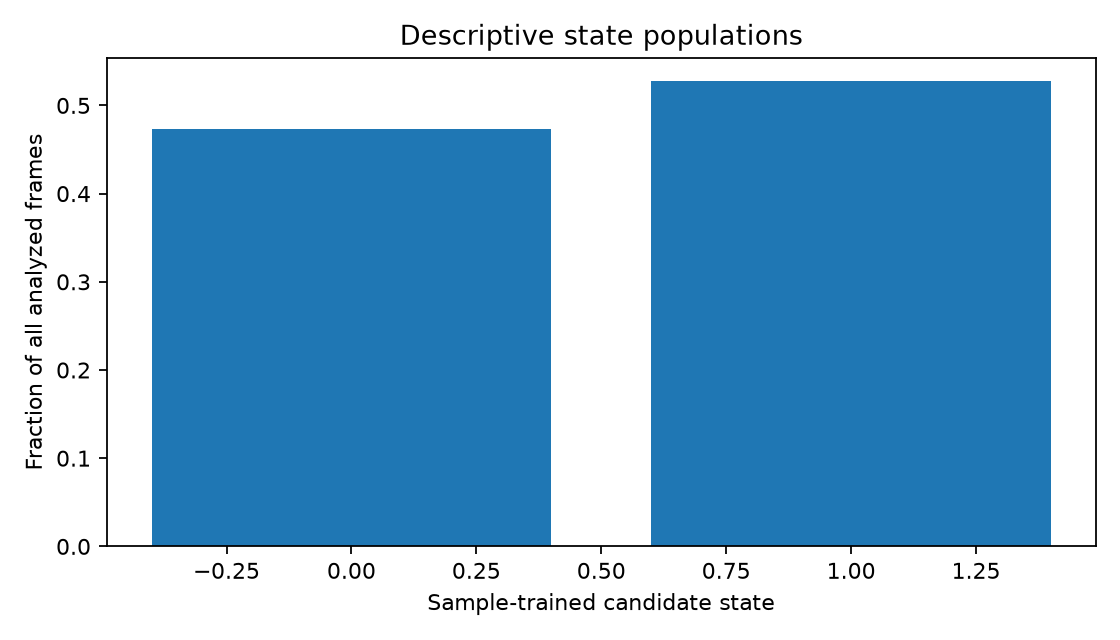

In [3]:
import pandas as pd
from IPython.display import Image, display

# 1. Check generated streaming artifacts
print("Generated Artifacts:")
for item in sorted(analysis_out.iterdir()):
    if item.is_file():
        size_kb = item.stat().st_size / 1024
        print(f"  {item.name:25s} ({size_kb:6.1f} KB)")

# 2. Display state populations table
pop_file = analysis_out / "state_populations.csv"
if pop_file.is_file():
    print("\nState Populations:")
    df_pop = pd.read_csv(pop_file)
    display(df_pop)

# 3. Display top variable features table
feat_file = analysis_out / "feature_summary.csv"
if feat_file.is_file():
    print("\nTop Variable Features:")
    df_feat = pd.read_csv(feat_file)
    display(df_feat.head(5))

# 4. Display state populations plot generated by analyze_stream
pop_img = analysis_out / "state_populations.png"
if pop_img.is_file():
    print("\nState Populations Distribution:")
    display(Image(filename=str(pop_img)))

## 5. Visualizing Conformational State Separation in Principal Component Space

By accumulating state assignments and principal components across streaming chunks, we project the trajectory into conformational space without loading the full trajectory matrix into memory.

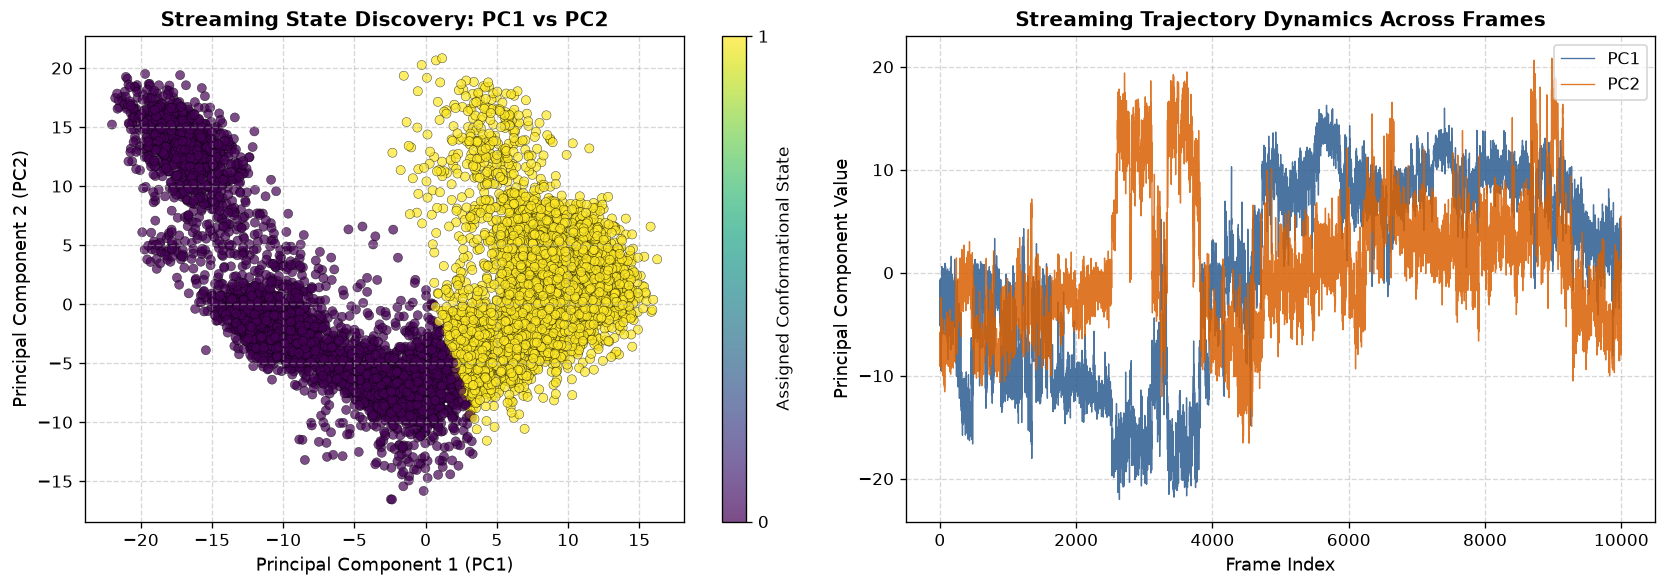

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

# Aggregate assignment chunks to visualize the low-dimensional projection
assignment_files = sorted((analysis_out / "assignments").glob("*.csv"))
df_assign = pd.concat([pd.read_csv(f) for f in assignment_files], ignore_index=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Scatter plot: PC1 vs PC2 colored by conformational state
scatter = ax1.scatter(
    df_assign["PC1"],
    df_assign["PC2"],
    c=df_assign["State"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="k",
    linewidths=0.3,
    s=30,
)
ax1.set_xlabel("Principal Component 1 (PC1)", fontsize=11)
ax1.set_ylabel("Principal Component 2 (PC2)", fontsize=11)
ax1.set_title("Streaming State Discovery: PC1 vs PC2", fontsize=12, fontweight="bold")
cbar = plt.colorbar(scatter, ax=ax1, ticks=range(analysis_config.states))
cbar.set_label("Assigned Conformational State", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.5)

# Trajectory trace: PC1 over frame index
ax2.plot(df_assign["frame_index"], df_assign["PC1"], color="#2b5c8f", lw=0.8, alpha=0.85, label="PC1")
ax2.plot(df_assign["frame_index"], df_assign["PC2"], color="#d95f02", lw=0.8, alpha=0.85, label="PC2")
ax2.set_xlabel("Frame Index", fontsize=11)
ax2.set_ylabel("Principal Component Value", fontsize=11)
ax2.set_title("Streaming Trajectory Dynamics Across Frames", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", frameon=True)

plt.tight_layout()
display(fig)
plt.close(fig)